In [1]:
from random import seed
from backtracking import juego_bt
from pl import juego_pl
from aproximaciones import aprox_greedy, aprox_gringo_hinz, aprox_pricing_method
from leer_archivo import *

from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import scipy as sp
import glob

from util import time_algorithm

seed(12345)
np.random.seed(12345)

sns.set_theme()

In [2]:
def dimensiones_tablero(ruta):
    tablero = leer_archivo(ruta)
    return len(tablero), len(tablero[0])

def devolver_filas(tablero, colores):
    _, _, _, vacias = construir_solucion(tablero, colores)
    return len(vacias)

# Manejables
rutas_manejables = glob.glob("../tp3_test/propios/manejables/*.txt")
rutas_manejables = sorted(rutas_manejables, key=lambda r: dimensiones_tablero(r)[1])
indices_manejables = range(len(rutas_manejables))
ms_manejables = [dimensiones_tablero(r)[1] for r in rutas_manejables]
x_m = np.array(sorted(set(ms_manejables)), dtype=float)

# Masivos
rutas_masivos = glob.glob("../tp3_test/propios/masivos/*.txt")
rutas_masivos = sorted(rutas_masivos, key=lambda r: dimensiones_tablero(r)[0] * dimensiones_tablero(r)[1])
dimensiones_masivos = [dimensiones_tablero(r) for r in rutas_masivos]
x_masivos = np.array([n * m for n, m in dimensiones_masivos], dtype=float)
x_m_masivos = np.array([m for n, m in dimensiones_masivos], dtype=float)
indices_masivos = range(len(rutas_masivos))

Todos los resultados de los algoritmos

In [3]:
def medir_promedio_por_m(algoritmo):
    res = time_algorithm(algoritmo, indices_manejables, lambda i: [leer_archivo(rutas_manejables[i])])

    tiempos_por_m = {}
    for i in indices_manejables:
        m = ms_manejables[i]
        if m not in tiempos_por_m:
            tiempos_por_m[m] = []
        tiempos_por_m[m].append(res[i])

    return np.array([np.mean(tiempos_por_m[int(m)]) for m in x_m], dtype=float)

y_bt = medir_promedio_por_m(juego_bt)
y_pl = medir_promedio_por_m(juego_pl)
y_greedy = medir_promedio_por_m(aprox_greedy)
y_gringo = medir_promedio_por_m(aprox_gringo_hinz)
y_pricing = medir_promedio_por_m(aprox_pricing_method)

Ajuste exponencial: c1 = 1.89e-05, b = 1.3740, c2 = -1.15e-02
Error cuadrático total (exponencial): 3.556097e+00
Error cuadrático total (polinomial m^3): 4.365208e+00


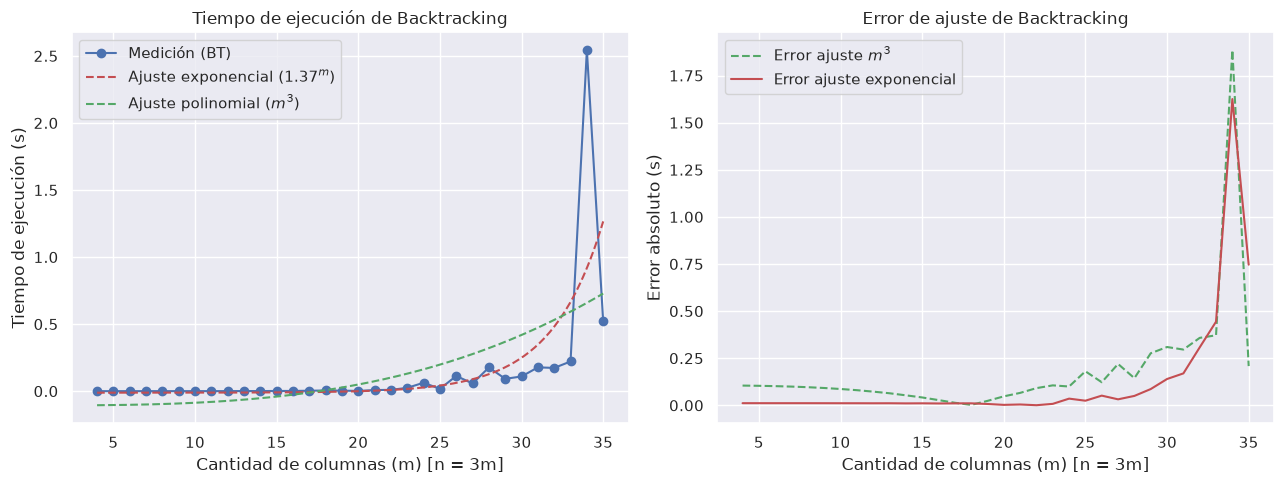

In [4]:
f_exp = lambda m, c1, b, c2: c1 * (b ** m) + c2
f_pol = lambda m, c1, c2: c1 * (m ** 3) + c2

c_exp, _ = sp.optimize.curve_fit(f_exp, x_m, y_bt, p0=[1e-6, 1.5, 0.0], bounds=([0.0, 1.0, -np.inf], [np.inf, 2.5, np.inf]),maxfev=10000)
c_pol, _ = sp.optimize.curve_fit(f_pol, x_m, y_bt)

err_exp = np.abs(f_exp(x_m, *c_exp) - y_bt)
err_pol = np.abs(f_pol(x_m, *c_pol) - y_bt)

print(f"Ajuste exponencial: c1 = {c_exp[0]:.2e}, b = {c_exp[1]:.4f}, c2 = {c_exp[2]:.2e}")
print(f"Error cuadrático total (exponencial): {np.sum(err_exp**2):.6e}")
print(f"Error cuadrático total (polinomial m^3): {np.sum(err_pol**2):.6e}")

xs = np.linspace(x_m.min(), x_m.max(), 200)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

axs[0].plot(x_m, y_bt, "o-", label="Medición (BT)")
axs[0].plot(xs, f_exp(xs, *c_exp), "r--", label=f"Ajuste exponencial (${c_exp[1]:.2f}^m$)")
axs[0].plot(xs, f_pol(xs, *c_pol), "g--", label="Ajuste polinomial ($m^3$)")
axs[0].set_title("Tiempo de ejecución de Backtracking")
axs[0].set_xlabel("Cantidad de columnas (m) [n = 3m]")
axs[0].set_ylabel("Tiempo de ejecución (s)")
axs[0].legend()

axs[1].plot(x_m, err_pol, "g--", label="Error ajuste $m^3$")
axs[1].plot(x_m, err_exp, "r-", label="Error ajuste exponencial")
axs[1].set_title("Error de ajuste de Backtracking")
axs[1].set_xlabel("Cantidad de columnas (m) [n = 3m]")
axs[1].set_ylabel("Error absoluto (s)")
axs[1].legend()

plt.tight_layout()
None

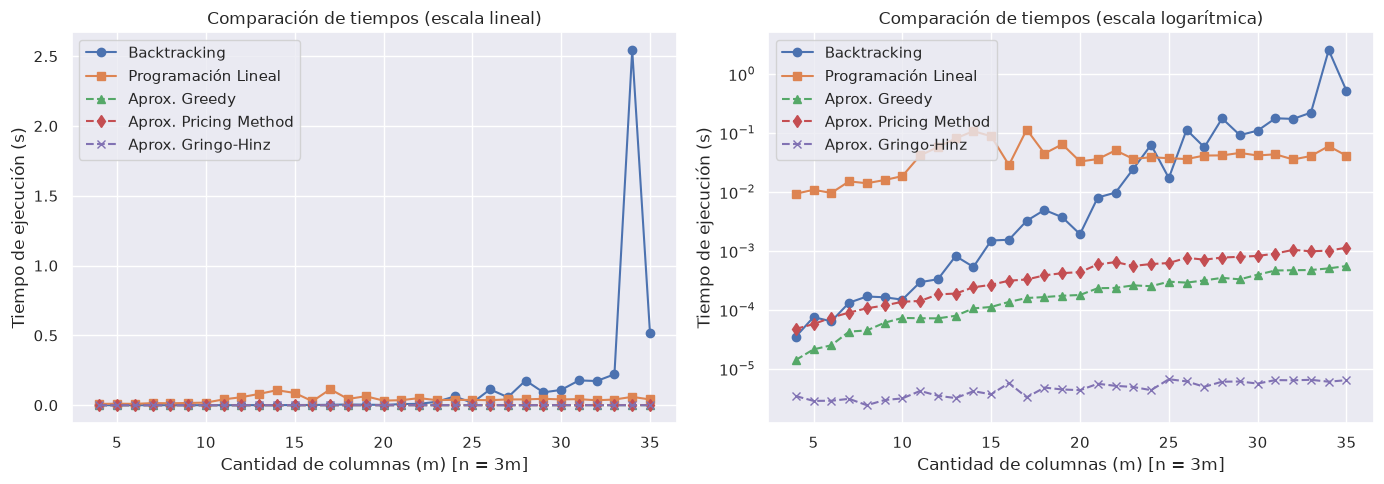

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for ax in axs:
    ax.plot(x_m, y_bt, "o-", label="Backtracking")
    ax.plot(x_m, y_pl, "s-", label="Programación Lineal")
    ax.plot(x_m, y_greedy, "^--", label="Aprox. Greedy")
    ax.plot(x_m, y_pricing, "d--", label="Aprox. Pricing Method")
    ax.plot(x_m, y_gringo, "x--", label="Aprox. Gringo-Hinz")
    ax.set_xlabel("Cantidad de columnas (m) [n = 3m]")
    ax.set_ylabel("Tiempo de ejecución (s)")
    ax.legend()

axs[0].set_title("Comparación de tiempos (escala lineal)")
axs[1].set_yscale("log")
axs[1].set_title("Comparación de tiempos (escala logarítmica)")

plt.tight_layout()
None

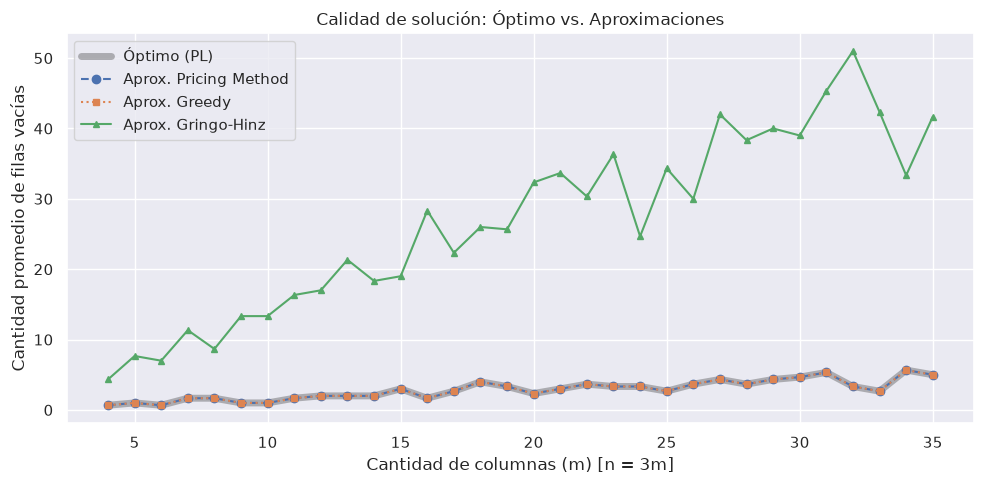

In [6]:
tableros_manejables = [leer_archivo(r) for r in rutas_manejables]

def calidad_promedio_por_m(algoritmo):
    filas_por_m = {}
    for i in indices_manejables:
        m = ms_manejables[i]
        if m not in filas_por_m:
            filas_por_m[m] = []
        tablero = tableros_manejables[i]
        filas_por_m[m].append(devolver_filas(tablero, algoritmo(tablero)))
    return np.array([np.mean(filas_por_m[int(m)]) for m in x_m], dtype=float)

vacias_opt = calidad_promedio_por_m(juego_pl)
vacias_greedy = calidad_promedio_por_m(aprox_greedy)
vacias_pricing = calidad_promedio_por_m(aprox_pricing_method)
vacias_gringo = calidad_promedio_por_m(aprox_gringo_hinz)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_m, vacias_opt, "k-", lw=5, alpha=0.3, label="Óptimo (PL)")
ax.plot(x_m, vacias_pricing, "o--", ms=6, label="Aprox. Pricing Method")
ax.plot(x_m, vacias_greedy, "s:", ms=5, label="Aprox. Greedy")
ax.plot(x_m, vacias_gringo, "^-", ms=5, label="Aprox. Gringo-Hinz")

ax.set_xlabel("Cantidad de columnas (m) [n = 3m]")
ax.set_ylabel("Cantidad promedio de filas vacías")
ax.set_title("Calidad de solución: Óptimo vs. Aproximaciones")
ax.legend()

plt.tight_layout()
None

In [7]:
f_n = lambda x, c1, c2: c1 * x + c2

res_greedy_m = time_algorithm(aprox_greedy, indices_masivos, lambda i: [leer_archivo(rutas_masivos[i])])
res_gringo_m = time_algorithm(aprox_gringo_hinz, indices_masivos, lambda i: [leer_archivo(rutas_masivos[i])])
res_pricing_m = time_algorithm(aprox_pricing_method, indices_masivos, lambda i: [leer_archivo(rutas_masivos[i])])

y_greedy_m = np.array([res_greedy_m[i] for i in indices_masivos], dtype=float)
y_pricing_m = np.array([res_pricing_m[i] for i in indices_masivos], dtype=float)
y_gringo_m = np.array([res_gringo_m[i] for i in indices_masivos], dtype=float)

c_greedy, _ = sp.optimize.curve_fit(f_n, x_masivos, y_greedy_m)
c_pricing, _ = sp.optimize.curve_fit(f_n, x_masivos, y_pricing_m)
c_gringo, _ = sp.optimize.curve_fit(f_n, x_m_masivos, y_gringo_m)

print(f"Aprox. Greedy:  c1 = {c_greedy[0]:.2e}, c2 = {c_greedy[1]:.2e}")
print(f"Aprox. Pricing: c1 = {c_pricing[0]:.2e}, c2 = {c_pricing[1]:.2e}")
print(f"Aprox. Gringo:  c1 = {c_gringo[0]:.2e}, c2 = {c_gringo[1]:.2e}")

Aprox. Greedy:  c1 = 2.25e-07, c2 = -3.66e-03
Aprox. Pricing: c1 = 2.82e-07, c2 = 1.04e-02
Aprox. Gringo:  c1 = 1.04e-07, c2 = 1.25e-05


Error cuadrático total Greedy:  1.488164e-02
Error cuadrático total Pricing: 8.151859e-02
Error cuadrático total Gringo:  1.993266e-08


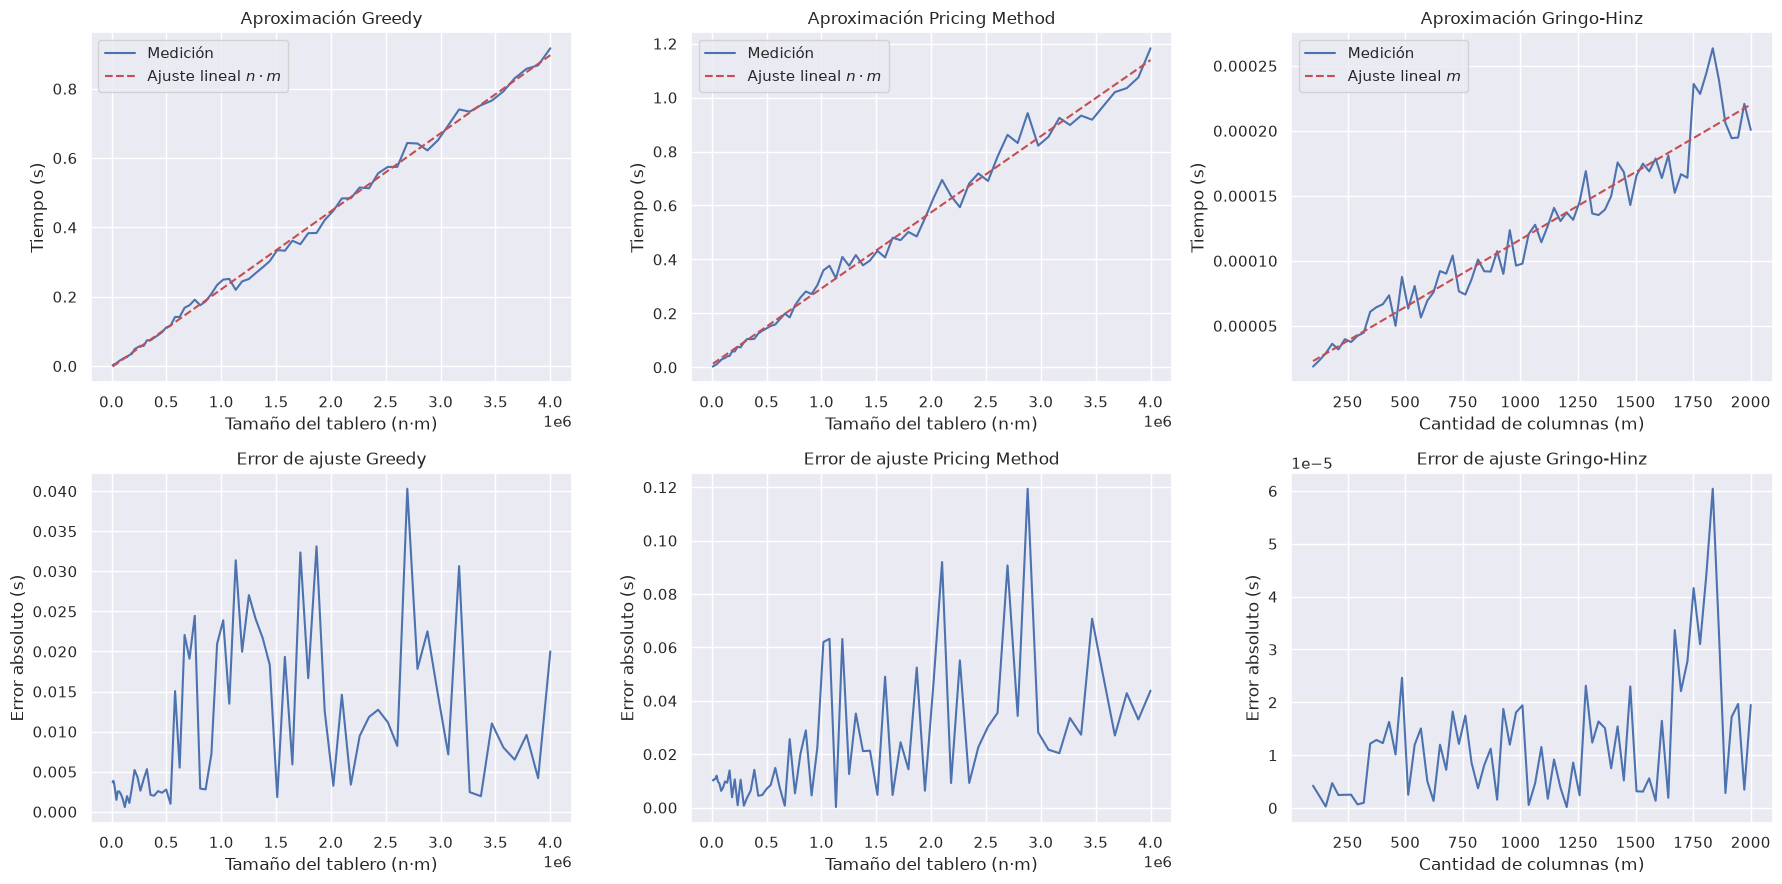

In [8]:
orden_m = np.argsort(x_m_masivos)

err_greedy_m = np.abs(f_n(x_masivos, *c_greedy) - y_greedy_m)
err_pricing_m = np.abs(f_n(x_masivos, *c_pricing) - y_pricing_m)
err_gringo_m = np.abs(f_n(x_m_masivos[orden_m], *c_gringo) - y_gringo_m[orden_m])

print(f"Error cuadrático total Greedy:  {np.sum(err_greedy_m**2):.6e}")
print(f"Error cuadrático total Pricing: {np.sum(err_pricing_m**2):.6e}")
print(f"Error cuadrático total Gringo:  {np.sum(err_gringo_m**2):.6e}")

fig, axs = plt.subplots(2, 3, figsize=(18, 9))

axs[0, 0].plot(x_masivos, y_greedy_m, label="Medición")
axs[0, 0].plot(x_masivos, f_n(x_masivos, *c_greedy), "r--", label=r"Ajuste lineal $n \cdot m$")
axs[0, 0].set_title("Aproximación Greedy")
axs[0, 0].set_xlabel("Tamaño del tablero (n·m)")
axs[0, 0].set_ylabel("Tiempo (s)")
axs[0, 0].legend()

axs[0, 1].plot(x_masivos, y_pricing_m, label="Medición")
axs[0, 1].plot(x_masivos, f_n(x_masivos, *c_pricing), "r--", label=r"Ajuste lineal $n \cdot m$")
axs[0, 1].set_title("Aproximación Pricing Method")
axs[0, 1].set_xlabel("Tamaño del tablero (n·m)")
axs[0, 1].set_ylabel("Tiempo (s)")
axs[0, 1].legend()

axs[0, 2].plot(x_m_masivos[orden_m], y_gringo_m[orden_m], label="Medición")
axs[0, 2].plot(x_m_masivos[orden_m], f_n(x_m_masivos[orden_m], *c_gringo), "r--", label=r"Ajuste lineal $m$")
axs[0, 2].set_title("Aproximación Gringo-Hinz")
axs[0, 2].set_xlabel("Cantidad de columnas (m)")
axs[0, 2].set_ylabel("Tiempo (s)")
axs[0, 2].legend()

axs[1, 0].plot(x_masivos, err_greedy_m)
axs[1, 0].set_title("Error de ajuste Greedy")
axs[1, 0].set_xlabel("Tamaño del tablero (n·m)")
axs[1, 0].set_ylabel("Error absoluto (s)")

axs[1, 1].plot(x_masivos, err_pricing_m)
axs[1, 1].set_title("Error de ajuste Pricing Method")
axs[1, 1].set_xlabel("Tamaño del tablero (n·m)")
axs[1, 1].set_ylabel("Error absoluto (s)")

axs[1, 2].plot(x_m_masivos[orden_m], err_gringo_m)
axs[1, 2].set_title("Error de ajuste Gringo-Hinz")
axs[1, 2].set_xlabel("Cantidad de columnas (m)")
axs[1, 2].set_ylabel("Error absoluto (s)")

plt.tight_layout()
None

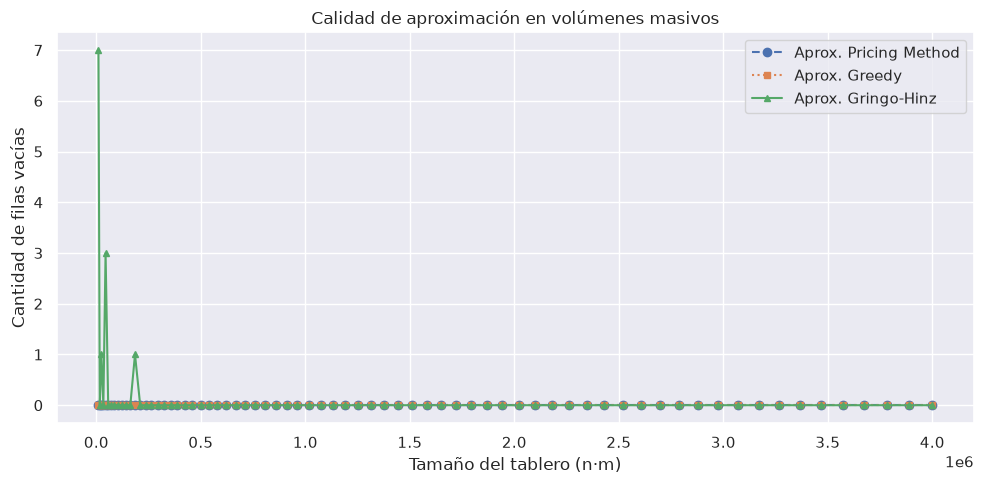

In [9]:
vacias_greedy_m = []
vacias_pricing_m = []
vacias_gringo_m = []

for ruta in rutas_masivos:
    tablero = leer_archivo(ruta)
    vacias_greedy_m.append(devolver_filas(tablero, aprox_greedy(tablero)))
    vacias_pricing_m.append(devolver_filas(tablero, aprox_pricing_method(tablero)))
    vacias_gringo_m.append(devolver_filas(tablero, aprox_gringo_hinz(tablero)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_masivos, vacias_pricing_m, "o--", ms=6, label="Aprox. Pricing Method")
ax.plot(x_masivos, vacias_greedy_m, "s:", ms=5, label="Aprox. Greedy")
ax.plot(x_masivos, vacias_gringo_m, "^-", ms=5, label="Aprox. Gringo-Hinz")

ax.set_xlabel("Tamaño del tablero (n·m)")
ax.set_ylabel("Cantidad de filas vacías")
ax.set_title("Calidad de aproximación en volúmenes masivos")
ax.legend()

plt.tight_layout()
None